# Local compact nonlinear reproduction

Isolated copy of Notebook 16: unchanged 58-feature L2 and Huber specifications and their fixed 50/50 log blends. The 99-feature candidate is omitted. Uses the verified rebuilt panel and frozen historical ridge forecasts. Adds sample, model, preprocessing and row-alignment records. Historical research outputs remain unchanged.

2022-2024 are development years; 2025 is previously inspected confirmation evidence. This is a reproduction on the current data snapshot, not a new holdout or a guarantee of historical bitwise identity. Historical training samples were not retained.


# 16 — Nonlinear residual-model challengers

This notebook tests whether gradient-boosted trees add useful nonlinear structure beyond the frozen global ridge benchmark.

Experimental discipline:

- The benchmark from Notebook 09 remains frozen and is never refit here.
- Every challenger predicts the residual from the trailing 20-observation median auction volume.
- Five-year rolling training windows and immediately preceding validation years match the benchmark design.
- 2022–2024 are development years; 2025 is reported separately as confirmation evidence.
- Hyperparameters are selected using historical validation data only.
- A replacement must improve development log RMSE by at least 0.002, remain stable in every development year, and pass a paired date-block log-MAE test.

In [1]:
from pathlib import Path
import gc
import json
import sys
import warnings

import duckdb
import lightgbm as lgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 180)
pd.set_option("display.max_rows", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (13, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor, forecast_metrics

PANEL = PROJECT_ROOT / "outputs" / "reproduction" / "01_daily_panel" / "enriched_daily_panel.parquet"
CATALOG = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "approved_enriched_daily_features.csv"
BENCHMARK_JSON = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists" / "frozen_global_benchmark.json"
BENCHMARK_PREDICTIONS = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists" / "predictions"
OUT = PROJECT_ROOT / "outputs" / "reproduction" / "03_compact_nonlinear"
PREDICTIONS = OUT / "predictions"
OUT.mkdir(parents=True, exist_ok=True)
PREDICTIONS.mkdir(parents=True, exist_ok=True)

if not PANEL.exists() or not BENCHMARK_JSON.exists():
    raise FileNotFoundError("Run Notebooks 05 and 09 before Notebook 16.")

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

with open(BENCHMARK_JSON) as handle:
    frozen = json.load(handle)
CHAMPION = frozen["champion"]

catalog = pd.read_csv(CATALOG)
FEATURES = catalog["variable"].tolist()
FEATURE_GROUPS = catalog.groupby("group")["variable"].apply(list).to_dict()

BOOLEAN_FEATURES = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]

CHAMPION_FEATURES = frozen["features"]
assert len(CHAMPION_FEATURES) == 58
assert len(FEATURES) == 99

print(f"Frozen benchmark: {CHAMPION}")
print(f"LightGBM version: {lgb.__version__}")
print(f"Feature sets: compact={len(CHAMPION_FEATURES)}, full={len(FEATURES)}")
SAMPLES = OUT / "samples"
MODELS = OUT / "models"
SAMPLES.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
def progress(message):
    from datetime import datetime, timezone
    line = datetime.now(timezone.utc).isoformat() + " " + message
    print(line, flush=True)
    with (OUT / "progress.log").open("a") as handle:
        handle.write(line + "\n")
def save_sample(frame, label):
    path = SAMPLES / (label + ".parquet")
    con.register("sample_snapshot", frame)
    con.execute(f"COPY sample_snapshot TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.unregister("sample_snapshot")
    return path
progress("Local compact nonlinear reproduction started")


Matplotlib is building the font cache; this may take a moment.


Frozen benchmark: rolling5_residual_auction_calendar_liquidity
LightGBM version: 4.7.0
Feature sets: compact=58, full=99
2026-11-03T01:47:02.956622+00:00 Local compact nonlinear reproduction started


## Prespecified challenger design

In [2]:
TEST_YEARS = [2022, 2023, 2024, 2025]
DEVELOPMENT_YEARS = [2022, 2023, 2024]
CONFIRMATION_YEAR = 2025
TUNE_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
SEED = 20261018
LEAF_GRID = [15, 31, 63]

CHALLENGERS = {
    "lgbm_residual_58_l2": {"features": CHAMPION_FEATURES, "objective": "regression"},
    "lgbm_residual_58_huber": {"features": CHAMPION_FEATURES, "objective": "huber"},
}

CONTEXT = [
    "date", "permno", "auction_volume", "log1p_auction_volume",
    "median20_auction_volume", "size_percentile", "liquidity_percentile",
    "auction_intensity_percentile", "prior_auction_observations",
    "quarterly_options_expiry", "monthly_options_expiry",
    "is_last_trading_day_month", "is_early_close",
]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)

design = pd.DataFrame([
    {"candidate": name, "objective": spec["objective"], "source_feature_count": len(spec["features"])}
    for name, spec in CHALLENGERS.items()
])
display(design)
design.to_csv(OUT / "challenger_specifications.csv", index=False)


,candidate,objective,source_feature_count
0,lgbm_residual_58_l2,regression,58
1,lgbm_residual_58_huber,huber,58


## Leakage-safe loading and fitting helpers

In [3]:
def load_period(start_date, end_date, sample_rows=None, seed=SEED):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS}
            FROM read_parquet('{PANEL}')
            WHERE eligible_target
              AND date >= DATE '{start_date}' AND date < DATE '{end_date}'
        ) {sample_clause}
    """)

def feature_mask(prep, source_features):
    allowed = set(source_features)
    return np.array([source in allowed for source in prep["output_sources"]])

def residual_target_and_base(train, score):
    fallback = float(np.median(train["auction_volume"]))
    train_base = train["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    score_base = score["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    target = train["log1p_auction_volume"].to_numpy(dtype=float) - np.log1p(train_base)
    return target, np.log1p(score_base)

def model_params(objective, leaves, seed, n_estimators=2000):
    return {
        "objective": objective,
        "n_estimators": n_estimators,
        "learning_rate": 0.03,
        "num_leaves": leaves,
        "min_child_samples": 500,
        "max_bin": 127,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.1,
        "reg_lambda": 5.0,
        "random_state": seed,
        "n_jobs": 4,
        "deterministic": True,
        "force_col_wise": True,
        "verbosity": -1,
    }

def fit_validation_model(x_train, y_train, x_validation, y_validation, objective, leaves, seed):
    model = lgb.LGBMRegressor(**model_params(objective, leaves, seed))
    model.fit(
        x_train, y_train,
        eval_set=[(x_validation, y_validation)],
        eval_metric="rmse",
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
    )
    return model

def final_log_prediction(model, matrix, base_log, train_log):
    prediction = base_log + model.predict(matrix)
    lo, hi = np.quantile(train_log, [0.001, 0.999])
    return np.clip(prediction, lo, hi)

def load_benchmark_predictions(year):
    path = BENCHMARK_PREDICTIONS / f"global_finalist_predictions_{year}.parquet"
    if not path.exists():
        raise FileNotFoundError(path)
    return sql(f'SELECT date, permno, "{CHAMPION}" AS frozen_prediction FROM read_parquet(\'{path}\')')


## Nested validation and rolling out-of-time predictions

In [4]:
metric_rows = []
validation_rows = []
importance_rows = []

for test_year in TEST_YEARS:
    progress(f"Starting fold {test_year}")
    validation_year = test_year - 1

    tune_train = load_period(
        f"{validation_year - 5}-01-01", f"{validation_year}-01-01",
        TUNE_ROWS, SEED + test_year,
    )
    validation = load_period(
        f"{validation_year}-01-01", f"{test_year}-01-01",
        VALIDATION_ROWS, SEED + 100 + test_year,
    )
    save_sample(tune_train, f"{test_year}_tune")
    save_sample(validation, f"{test_year}_validation")
    progress(f"Fold {test_year}: loaded historical tuning and validation rows")
    x_tune, prep_tune = fit_preprocessor(
        tune_train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    x_validation = apply_preprocessor(
        validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    y_tune_residual, validation_base_log = residual_target_and_base(tune_train, validation)
    y_validation_log = validation["log1p_auction_volume"].to_numpy(dtype=float)
    y_validation_residual = y_validation_log - validation_base_log

    selected = {}
    for candidate, spec in CHALLENGERS.items():
        mask = feature_mask(prep_tune, spec["features"])
        best = None
        for leaves in LEAF_GRID:
            progress(f"Fold {test_year}: tuning {candidate}, leaves={leaves}")
            model = fit_validation_model(
                x_tune[:, mask], y_tune_residual,
                x_validation[:, mask], y_validation_residual,
                spec["objective"], leaves, SEED + test_year + leaves,
            )
            prediction_log = final_log_prediction(
                model, x_validation[:, mask], validation_base_log,
                tune_train["log1p_auction_volume"].to_numpy(dtype=float),
            )
            rmse = float(np.sqrt(np.mean((y_validation_log - prediction_log) ** 2)))
            row = {
                "test_year": test_year, "validation_year": validation_year,
                "candidate": candidate, "num_leaves": leaves,
                "best_iteration": int(model.best_iteration_), "validation_rmse_log": rmse,
            }
            validation_rows.append(row)
            if best is None or rmse < best["validation_rmse_log"]:
                best = row
        selected[candidate] = best
        progress(f"Fold {test_year}: selected {candidate}, leaves={best['num_leaves']}, iterations={best['best_iteration']}")

    del tune_train, validation, x_tune, x_validation, y_tune_residual, y_validation_residual
    gc.collect()

    refit = load_period(
        f"{test_year - 5}-01-01", f"{test_year}-01-01",
        REFIT_ROWS, SEED + 200 + test_year,
    )
    test = load_period(f"{test_year}-01-01", f"{test_year + 1}-01-01")
    save_sample(refit, f"{test_year}_refit")
    progress(f"Fold {test_year}: refitting on {len(refit):,} rows; scoring {len(test):,} rows")
    x_refit, prep = fit_preprocessor(
        refit, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    x_test = apply_preprocessor(
        test, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
    )
    (MODELS / f"preprocessor_{test_year}.json").write_text(json.dumps(prep, indent=2))
    y_refit_residual, test_base_log = residual_target_and_base(refit, test)
    (MODELS / f"reconstruction_{test_year}.json").write_text(json.dumps({
        "fallback": float(np.median(refit["auction_volume"])),
        "clip_log": np.quantile(refit["log1p_auction_volume"], [0.001, 0.999]).tolist(),
        "selected": selected,
    }, indent=2))
    refit_log = refit["log1p_auction_volume"].to_numpy(dtype=float)
    y_test_raw = test["auction_volume"].to_numpy(dtype=float)

    output = test[CONTEXT].copy()
    benchmark = load_benchmark_predictions(test_year)
    original_keys = output[["date", "permno"]].copy()
    output = output.merge(benchmark, on=["date", "permno"], how="left", validate="one_to_one", sort=False)
    assert output[["date", "permno"]].equals(original_keys), "Merge changed row ordering"
    assert np.array_equal(output["auction_volume"].to_numpy(), y_test_raw)
    if output["frozen_prediction"].isna().any():
        raise AssertionError("Frozen benchmark predictions did not align with the test panel.")
    metric_rows.append({
        "test_year": test_year, "candidate": CHAMPION, "model_family": "frozen ridge",
        **forecast_metrics(y_test_raw, output["frozen_prediction"]),
    })

    for candidate, spec in CHALLENGERS.items():
        choice = selected[candidate]
        mask = feature_mask(prep, spec["features"])
        iterations = max(25, choice["best_iteration"])
        model = lgb.LGBMRegressor(**model_params(
            spec["objective"], choice["num_leaves"], SEED + 300 + test_year,
            n_estimators=iterations,
        ))
        progress(f"Fold {test_year}: final fit {candidate}, iterations={iterations}")
        model.fit(x_refit[:, mask], y_refit_residual)
        model.booster_.save_model(str(MODELS / f"{candidate}_{test_year}.txt"))
        (MODELS / f"feature_columns_{candidate}_{test_year}.json").write_text(json.dumps({
            "output_names": np.array(prep["output_names"])[mask].tolist(),
            "source_features": spec["features"],
        }, indent=2))
        prediction_log = final_log_prediction(model, x_test[:, mask], test_base_log, refit_log)
        prediction_raw = np.maximum(np.expm1(prediction_log), 0)
        output[candidate] = prediction_raw
        metric_rows.append({
            "test_year": test_year, "candidate": candidate, "model_family": "LightGBM",
            **forecast_metrics(y_test_raw, prediction_raw),
        })

        names = np.array(prep["output_names"])[mask]
        sources = np.array(prep["output_sources"])[mask]
        fold_importance = pd.DataFrame({
            "output_feature": names, "source_feature": sources,
            "gain": model.booster_.feature_importance(importance_type="gain"),
            "split": model.booster_.feature_importance(importance_type="split"),
        }).groupby("source_feature", as_index=False)[["gain", "split"]].sum()
        fold_importance["test_year"] = test_year
        fold_importance["candidate"] = candidate
        importance_rows.extend(fold_importance.to_dict("records"))

        blend_name = candidate.replace("lgbm_", "blend50_")
        blend_log = 0.5 * np.log1p(output["frozen_prediction"].to_numpy(dtype=float)) + 0.5 * prediction_log
        blend_raw = np.maximum(np.expm1(blend_log), 0)
        output[blend_name] = blend_raw
        metric_rows.append({
            "test_year": test_year, "candidate": blend_name, "model_family": "50/50 log blend",
            **forecast_metrics(y_test_raw, blend_raw),
        })

    path = PREDICTIONS / f"nonlinear_challenger_predictions_{test_year}.parquet"
    con.register("prediction_output", output)
    con.execute(f"COPY prediction_output TO '{path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.unregister("prediction_output")
    pd.DataFrame(metric_rows).to_csv(OUT / "nonlinear_candidate_metrics.csv", index=False)
    pd.DataFrame(validation_rows).to_csv(OUT / "nonlinear_hyperparameter_validation.csv", index=False)
    progress(f"Fold {test_year}: saved {len(output):,} complete forecasts")

    del refit, test, x_refit, x_test, y_refit_residual, output, benchmark
    gc.collect()

metrics = pd.DataFrame(metric_rows)
validation_results = pd.DataFrame(validation_rows)
importance = pd.DataFrame(importance_rows)
metrics.to_csv(OUT / "nonlinear_candidate_metrics.csv", index=False)
validation_results.to_csv(OUT / "nonlinear_hyperparameter_validation.csv", index=False)
importance.to_csv(OUT / "nonlinear_feature_importance.csv", index=False)

display(metrics.sort_values(["test_year", "rmse_log"]))


2026-11-03T01:47:02.981916+00:00 Starting fold 2022


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-11-03T01:47:11.849546+00:00 Fold 2022: loaded historical tuning and validation rows


2026-11-03T01:47:13.980844+00:00 Fold 2022: tuning lgbm_residual_58_l2, leaves=15


2026-11-03T01:47:28.689102+00:00 Fold 2022: tuning lgbm_residual_58_l2, leaves=31


... (60 outputs left out)

2026-11-03T02:00:57.505153+00:00 Fold 2025: final fit lgbm_residual_58_l2, iterations=1056


2026-11-03T02:01:12.756837+00:00 Fold 2025: final fit lgbm_residual_58_huber, iterations=1709


2026-11-03T02:01:39.686840+00:00 Fold 2025: saved 307,853 complete forecasts


,test_year,candidate,model_family,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
1,2022,lgbm_residual_58_l2,LightGBM,328634,"71,383.7846",0.3668,0.3556,0.5101,0.9535,-0.1466
2,2022,blend50_residual_58_l2,50/50 log blend,328634,"71,413.3014",0.3670,0.3525,0.5110,0.9535,-0.1513
4,2022,blend50_residual_58_huber,50/50 log blend,328634,"71,462.3778",0.3672,0.3525,0.5145,0.9530,-0.1558
3,2022,lgbm_residual_58_huber,LightGBM,328634,"71,084.4707",0.3653,0.3543,0.5147,0.9533,-0.1581
0,2022,rolling5_residual_auction_calendar_liquidity,frozen ridge,328634,"74,158.2867",0.3811,0.3638,0.5335,0.9490,-0.1444
6,2023,lgbm_residual_58_l2,LightGBM,318679,"77,549.0869",0.3520,0.3243,0.4609,0.9604,-0.1450
8,2023,lgbm_residual_58_huber,LightGBM,318679,"77,169.5199",0.3503,0.3233,0.4631,0.9604,-0.1568
7,2023,blend50_residual_58_l2,50/50 log blend,318679,"78,154.2600",0.3548,0.3236,0.4634,0.9600,-0.1478
9,2023,blend50_residual_58_huber,50/50 log blend,318679,"77,957.4504",0.3539,0.3229,0.4647,0.9600,-0.1533
5,2023,rolling5_residual_auction_calendar_liquidity,frozen ridge,318679,"81,455.0318",0.3697,0.3348,0.4837,0.9562,-0.1416


## Paired date-block bootstrap and replacement gate

In [5]:
PREDICTION_GLOB = str(PREDICTIONS / "nonlinear_challenger_predictions_*.parquet")
CANDIDATES = [c for c in metrics["candidate"].unique() if c != CHAMPION]

def bootstrap_mean_interval(values, seed, draws=2000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(draws)
    for draw in range(draws):
        means[draw] = rng.choice(values, size=len(values), replace=True).mean()
    return float(values.mean()), *np.quantile(means, [0.025, 0.975]).tolist()

bootstrap_rows = []
for candidate_number, candidate in enumerate(CANDIDATES):
    daily = sql(f"""
        SELECT date, year(date) AS test_year,
               avg(abs(ln(1 + "{candidate}") - log1p_auction_volume)
                 - abs(ln(1 + frozen_prediction) - log1p_auction_volume)) AS log_mae_difference
        FROM read_parquet('{PREDICTION_GLOB}')
        GROUP BY date, year(date)
        ORDER BY date
    """)
    for period, years in {
        "development_2022_2024": DEVELOPMENT_YEARS,
        "confirmation_2025": [CONFIRMATION_YEAR],
    }.items():
        values = daily.loc[daily["test_year"].isin(years), "log_mae_difference"].to_numpy()
        mean, low, high = bootstrap_mean_interval(values, SEED + candidate_number)
        bootstrap_rows.append({
            "candidate": candidate, "reference": CHAMPION, "period": period,
            "mean_difference": mean, "ci_2_5": low, "ci_97_5": high,
            "dates": len(values),
        })

bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT / "nonlinear_date_block_bootstrap.csv", index=False)

development = metrics[metrics["test_year"].isin(DEVELOPMENT_YEARS)].groupby(
    ["candidate", "model_family"], as_index=False
).agg(
    development_rmse_log=("rmse_log", "mean"),
    development_wape=("wape", "mean"),
    development_spearman=("spearman", "mean"),
    development_bias=("aggregate_bias", "mean"),
    worst_development_rmse=("rmse_log", "max"),
)
confirmation = metrics[metrics["test_year"] == CONFIRMATION_YEAR][
    ["candidate", "rmse_log", "wape", "spearman", "aggregate_bias"]
].rename(columns={
    "rmse_log": "confirmation_rmse_log", "wape": "confirmation_wape",
    "spearman": "confirmation_spearman", "aggregate_bias": "confirmation_bias",
})
dev_bootstrap = bootstrap[bootstrap["period"] == "development_2022_2024"][
    ["candidate", "mean_difference", "ci_2_5", "ci_97_5"]
]
decision = development.merge(confirmation, on="candidate", how="left").merge(
    dev_bootstrap, on="candidate", how="left"
)
benchmark_rmse = float(decision.loc[decision["candidate"] == CHAMPION, "development_rmse_log"].iloc[0])
decision["rmse_change_vs_frozen"] = decision["development_rmse_log"] - benchmark_rmse

annual = metrics[metrics["test_year"].isin(DEVELOPMENT_YEARS)].pivot(
    index="candidate", columns="test_year", values="rmse_log"
)
benchmark_annual = annual.loc[CHAMPION]
stable = annual.sub(benchmark_annual, axis=1).max(axis=1).le(0.002)
decision["stable_each_development_year"] = decision["candidate"].map(stable)
decision["practical_rmse_improvement"] = decision["rmse_change_vs_frozen"] <= -0.002
decision["paired_log_mae_significant"] = decision["ci_97_5"] < 0
decision["eligible_replacement"] = (
    decision["practical_rmse_improvement"]
    & decision["stable_each_development_year"]
    & decision["paired_log_mae_significant"].fillna(False)
)
decision.to_csv(OUT / "nonlinear_candidate_selection.csv", index=False)
display(decision.sort_values("development_rmse_log"))


,candidate,model_family,development_rmse_log,development_wape,development_spearman,development_bias,worst_development_rmse,confirmation_rmse_log,confirmation_wape,confirmation_spearman,confirmation_bias,mean_difference,ci_2_5,ci_97_5,rmse_change_vs_frozen,stable_each_development_year,practical_rmse_improvement,paired_log_mae_significant,eligible_replacement
3,lgbm_residual_58_l2,LightGBM,0.4694,0.3545,0.9582,-0.1440,0.5101,0.4306,0.3294,0.9620,-0.0890,-0.0067,-0.0118,-0.0024,-0.0182,True,True,True,True
1,blend50_residual_58_l2,50/50 log blend,0.4696,0.3550,0.9583,-0.1484,0.5110,0.4304,0.3311,0.9617,-0.0963,-0.0095,-0.0128,-0.0068,-0.0180,True,True,True,True
0,blend50_residual_58_huber,50/50 log blend,0.4714,0.3545,0.9582,-0.1543,0.5145,0.4309,0.3308,0.9617,-0.0988,-0.0101,-0.0132,-0.0076,-0.0163,True,True,True,True
2,lgbm_residual_58_huber,LightGBM,0.4721,0.3529,0.9582,-0.1569,0.5147,0.4321,0.3294,0.9618,-0.0941,-0.0082,-0.0132,-0.0043,-0.0156,True,True,True,True
4,rolling5_residual_auction_calendar_liquidity,frozen ridge,0.4876,0.3680,0.9549,-0.1438,0.5335,0.4451,0.3456,0.9588,-0.0962,NaN,NaN,NaN,0.0000,True,False,False,False


## Segment and tail diagnostics

In [6]:
prediction_columns = [CHAMPION] + CANDIDATES
segment_expressions = {
    "actual_tail": "CASE WHEN actual_percentile >= 0.99 THEN 'top_1pct' ELSE 'lower_99pct' END",
    "size": "CASE WHEN size_percentile < 0.33 THEN 'small' WHEN size_percentile < 0.67 THEN 'mid' ELSE 'large' END",
    "history": "CASE WHEN prior_auction_observations < 5 THEN 'cold_0_4' WHEN prior_auction_observations < 20 THEN 'developing_5_19' ELSE 'seasoned_20_plus' END",
    "event": "CASE WHEN quarterly_options_expiry THEN 'quarterly_expiry' WHEN monthly_options_expiry THEN 'monthly_expiry' WHEN is_last_trading_day_month THEN 'month_end' ELSE 'regular' END",
}

segment_queries = []
for candidate in prediction_columns:
    prediction = "frozen_prediction" if candidate == CHAMPION else f'"{candidate}"'
    for dimension, expression in segment_expressions.items():
        segment_queries.append(f"""
            SELECT '{candidate}' AS candidate, '{dimension}' AS dimension,
                   {expression} AS segment, count(*) AS observations,
                   sqrt(avg(pow(ln(1 + {prediction}) - log1p_auction_volume, 2))) AS rmse_log,
                   sum(abs({prediction} - auction_volume)) / sum(auction_volume) AS wape,
                   sum({prediction}) / sum(auction_volume) - 1 AS aggregate_bias
            FROM ranked GROUP BY 1, 2, 3
        """)

segment_diagnostics = sql(f"""
    WITH ranked AS (
        SELECT *, percent_rank() OVER (
            PARTITION BY year(date) ORDER BY auction_volume
        ) AS actual_percentile
        FROM read_parquet('{PREDICTION_GLOB}')
        WHERE year(date) IN (2022, 2023, 2024)
    )
    {" UNION ALL ".join(segment_queries)}
""")
segment_diagnostics.to_csv(OUT / "nonlinear_segment_diagnostics.csv", index=False)
display(segment_diagnostics.sort_values(["dimension", "segment", "rmse_log"]))


,candidate,dimension,segment,observations,rmse_log,wape,aggregate_bias
24,blend50_residual_58_l2,actual_tail,lower_99pct,953888,0.4575,0.3050,-0.0656
48,blend50_residual_58_huber,actual_tail,lower_99pct,953888,0.4587,0.3039,-0.0724
12,lgbm_residual_58_l2,actual_tail,lower_99pct,953888,0.4590,0.3066,-0.0576
36,lgbm_residual_58_huber,actual_tail,lower_99pct,953888,0.4607,0.3035,-0.0720
0,rolling5_residual_auction_calendar_liquidity,actual_tail,lower_99pct,953888,0.4737,0.3168,-0.0655
13,lgbm_residual_58_l2,actual_tail,top_1pct,9637,1.1463,0.5271,-0.4614
37,lgbm_residual_58_huber,actual_tail,top_1pct,9637,1.1924,0.5310,-0.4693
25,blend50_residual_58_l2,actual_tail,top_1pct,9637,1.2192,0.5349,-0.4526
49,blend50_residual_58_huber,actual_tail,top_1pct,9637,1.2450,0.5363,-0.4558
1,rolling5_residual_auction_calendar_liquidity,actual_tail,top_1pct,9637,1.3219,0.5513,-0.4325


## Comparison plot and conclusion

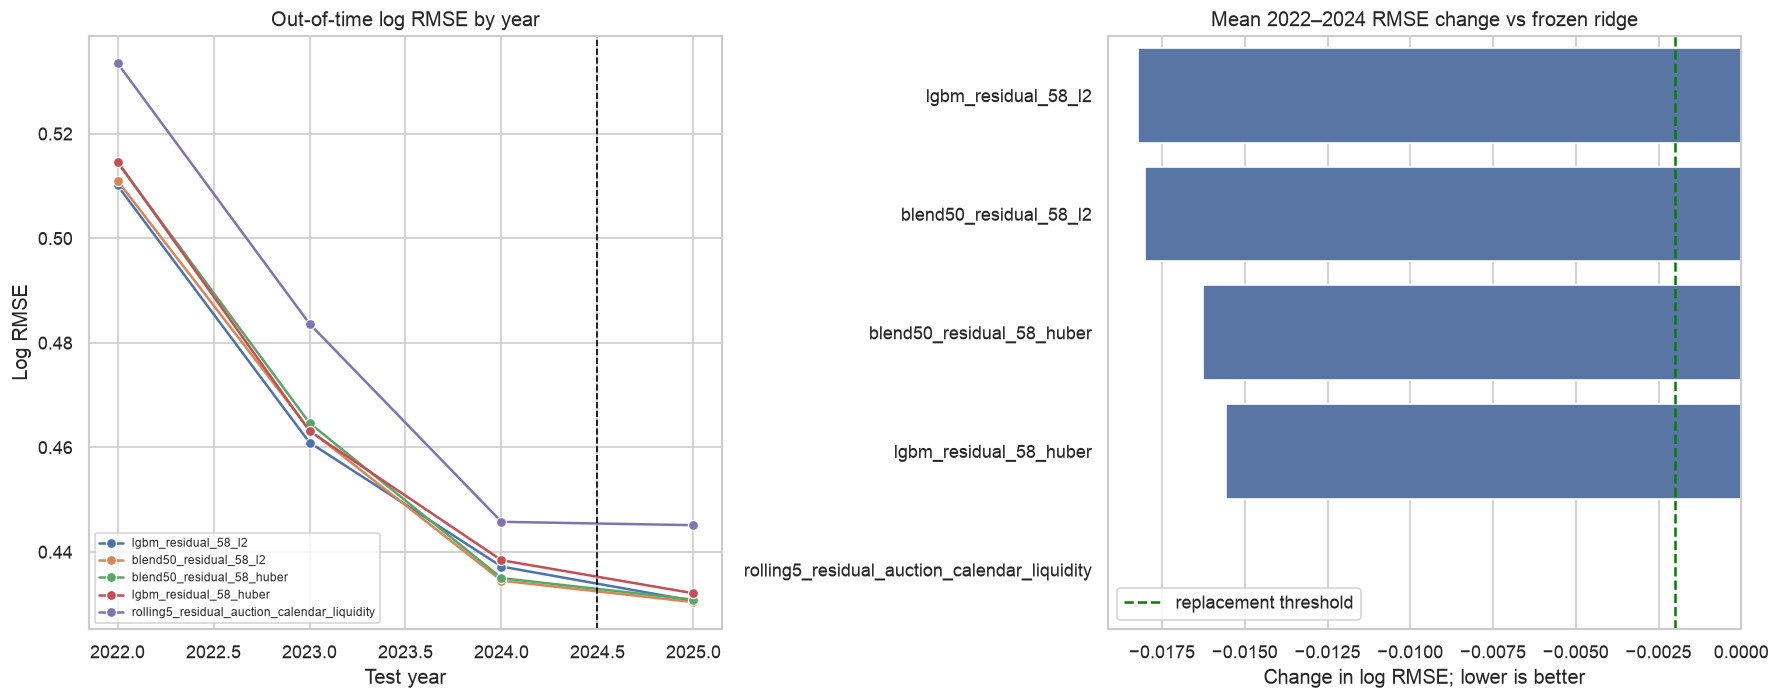

{'frozen_benchmark': 'rolling5_residual_auction_calendar_liquidity',
 'development_years': [2022, 2023, 2024],
 'confirmation_year': 2025,
 'eligible_replacements': ['blend50_residual_58_huber',
  'blend50_residual_58_l2',
  'lgbm_residual_58_huber',
  'lgbm_residual_58_l2'],
 'retain_frozen_benchmark': False,
 'best_development_candidate': 'lgbm_residual_58_l2'}

In [7]:
plot_order = decision.sort_values("development_rmse_log")["candidate"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.lineplot(
    data=metrics, x="test_year", y="rmse_log", hue="candidate",
    hue_order=plot_order, marker="o", ax=axes[0],
)
axes[0].axvline(2024.5, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Out-of-time log RMSE by year")
axes[0].set_xlabel("Test year")
axes[0].set_ylabel("Log RMSE")
axes[0].legend(fontsize=7, loc="best")

plot_data = decision.sort_values("development_rmse_log")
sns.barplot(data=plot_data, y="candidate", x="rmse_change_vs_frozen", ax=axes[1], color="#4c72b0")
axes[1].axvline(-0.002, color="green", linestyle="--", label="replacement threshold")
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Mean 2022–2024 RMSE change vs frozen ridge")
axes[1].set_xlabel("Change in log RMSE; lower is better")
axes[1].set_ylabel("")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "nonlinear_challenger_comparison.png", bbox_inches="tight")
plt.show()

eligible = decision.loc[decision["eligible_replacement"], "candidate"].tolist()
recommendation = {
    "frozen_benchmark": CHAMPION,
    "development_years": DEVELOPMENT_YEARS,
    "confirmation_year": CONFIRMATION_YEAR,
    "eligible_replacements": eligible,
    "retain_frozen_benchmark": len(eligible) == 0,
    "best_development_candidate": decision.sort_values("development_rmse_log").iloc[0]["candidate"],
}
with open(OUT / "nonlinear_model_recommendation.json", "w") as handle:
    json.dump(recommendation, handle, indent=2)
display(recommendation)
